# Plant Disease Dataset EDA

This notebook explores the `geraldmc/plantvillage-full` dataset for the plant disease detection project. The goal is to confirm the dataset structure, check class balance, understand the train/test split, and inspect a few examples before training a classifier.

Key questions we want to answer:
- What does the dataset look like at a high level?
- Are the classes balanced or heavily skewed?
- Which hosts and crops are represented?
- Do the sample images look consistent enough for model training?

In [19]:
%pip install roboflow dataset pandas matplotlib pillow tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 11.8 MB/s eta 0:00:00


## 1. Load the dataset

The next cell loads the public plant disease dataset from Hugging Face and stores it in a `datasets.DatasetDict` object. This gives us a quick view of the available splits and metadata columns before we flatten it for analysis.


In [1]:
from datasets import load_dataset

ds = load_dataset("geraldmc/plantvillage-full")


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/5.86k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  402MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  453MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/54304 [00:00<?, ? examples/s]

## 2. Review the dataset structure

`ds` contains the split structure and column schema. We use the dataset metadata to confirm the labels, image fields, and whether the dataset is already partitioned into train/validation/test subsets.


In [37]:
ds

DatasetDict({
    train: Dataset({
        features: ['image', 'class_label', 'class_idx', 'host', 'disease', 'split', 'leaf_id', 'leaf_grouped'],
        num_rows: 54304
    })
})

In [3]:
import pandas as pd
from datasets import concatenate_datasets

print(ds)                                   # splits and columns
d = concatenate_datasets(list(ds.values())) # one table; the train/test info is in the "split" column
d.features

DatasetDict({
    train: Dataset({
        features: ['image', 'class_label', 'class_idx', 'host', 'disease', 'split', 'leaf_id', 'leaf_grouped'],
        num_rows: 54304
    })
})


{'image': Image(mode=None, decode=True),
 'class_label': Value('string'),
 'class_idx': Value('int32'),
 'host': Value('string'),
 'disease': Value('string'),
 'split': Value('string'),
 'leaf_id': Value('string'),
 'leaf_grouped': Value('bool')}

## 3. Flatten the data for tabular analysis

The dataset is converted into a single pandas table so we can summarize counts, inspect metadata fields, and compute distribution statistics across disease classes and plant hosts.


In [4]:
#metadata only, no images
meta = d.remove_columns("image").to_pandas()
meta.head()

,class_label,class_idx,host,disease,split,leaf_id,leaf_grouped
0,Apple___Apple_scab,0,Apple,Apple scab,test,Apple___Apple_scab::leaf_79,True
1,Apple___Apple_scab,0,Apple,Apple scab,test,Apple___Apple_scab::leaf_19,True
2,Apple___Apple_scab,0,Apple,Apple scab,test,Apple___Apple_scab::leaf_39,True
3,Apple___Apple_scab,0,Apple,Apple scab,train,Apple___Apple_scab::leaf_25,True
4,Apple___Apple_scab,0,Apple,Apple scab,train,Apple___Apple_scab::leaf_102,True


## 4. Check metadata quality

A metadata-only table makes quality checks fast. We look for missing values, exact duplicate records, and the basic dataset dimensions before analyzing class balance.


In [10]:
quality_summary = pd.Series({
    "images": len(meta),
    "classes": meta["class_label"].nunique(),
    "hosts": meta["host"].nunique(),
    "duplicate_metadata_rows": meta.duplicated().sum(),
    "repeated_leaf_ids": meta["leaf_id"].duplicated().sum(),
})

print(quality_summary)
print("\nMissing values by column:")
display(meta.isna().sum().sort_values(ascending=False).to_frame("missing"))


images                     54304
classes                       38
hosts                         14
duplicate_metadata_rows    29919
repeated_leaf_ids          29919
dtype: int64

Missing values by column:


,missing
class_label,0
class_idx,0
host,0
disease,0
split,0
leaf_id,0
leaf_grouped,0


In [40]:
len(d)

54304

## 5. Check split and host composition

This section shows how images are distributed across splits and plant hosts. The split must remain separate for final evaluation, while host-level counts reveal whether some crops dominate the dataset.


In [41]:
meta.split.value_counts()

,count
split,
train,43356
test,10948


## 6. Check class balance across splits

Class counts should be compared within each split, not only across the full dataset. This helps identify rare classes and confirms that evaluation data contains enough examples for each label.


split,test,train
class_label,,
Apple___Apple_scab,123,507
Apple___Black_rot,124,497
Apple___Cedar_apple_rust,55,220
Apple___healthy,324,1321
Blueberry___healthy,278,1224
Cherry_(including_sour)___Powdery_mildew,252,800
Cherry_(including_sour)___healthy,179,675
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,103,410
Corn_(maize)___Common_rust_,238,954


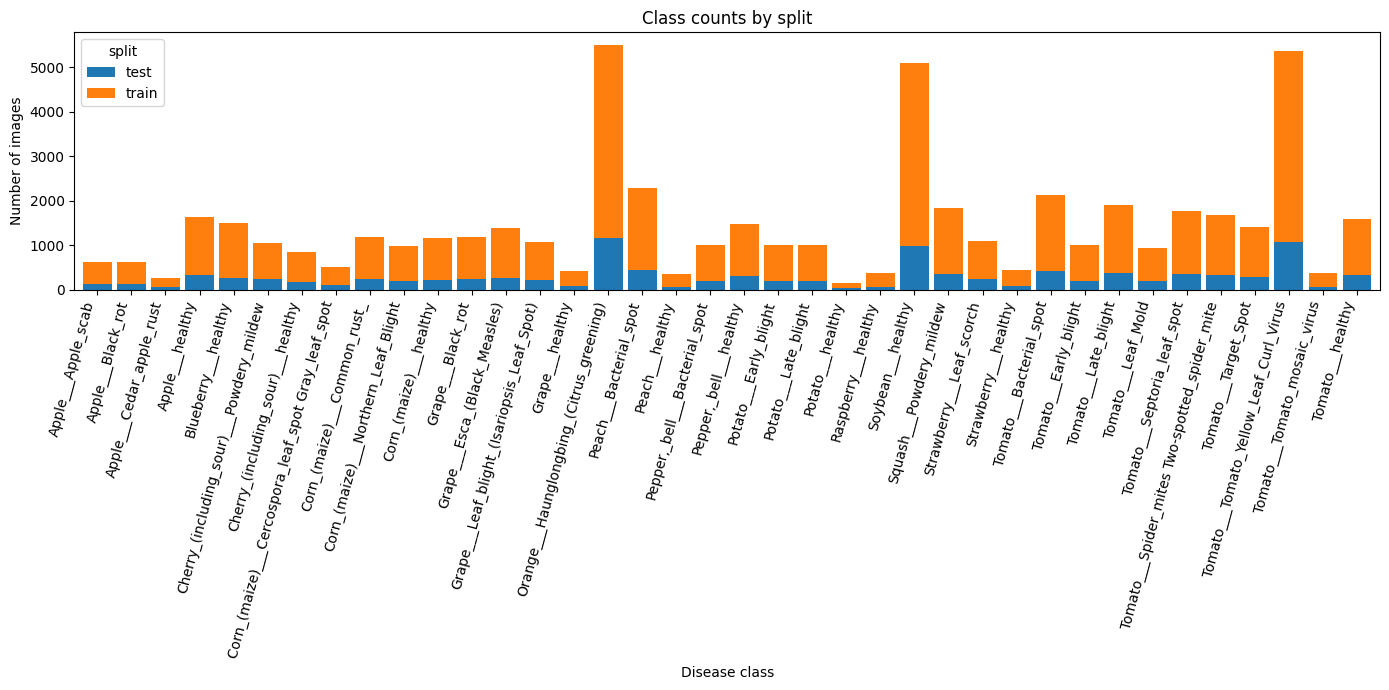

In [7]:
import matplotlib.pyplot as plt

split_class_counts = pd.crosstab(meta["class_label"], meta["split"])
display(split_class_counts)

ax = split_class_counts.plot(kind="bar", stacked=True, figsize=(14, 7), width=0.85)
ax.set_title("Class counts by split")
ax.set_xlabel("Disease class")
ax.set_ylabel("Number of images")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()


In [42]:
host_summary = meta.groupby("host").agg(
    images=("class_label", "size"),
    classes=("class_label", "nunique"),
    leaves=("leaf_id", "nunique"),
).sort_values("images", ascending=False)

display(host_summary)


,images,classes,leaves
host,,,
Raspberry,371,1,37
Blueberry,1502,1,160
Strawberry,1565,2,523
Squash,1835,1,1835
Cherry (including sour),1906,2,175
Potato,2152,3,538
"Pepper, bell",2474,2,857
Peach,2657,2,389
Apple,3171,4,1055


## 7. Visualize class frequency

The class-frequency plot makes long-tail behavior easy to spot. Large differences in sample counts may require class-weighted loss, balanced sampling, or targeted augmentation during training.


<Axes: title={'center': 'Images per class'}, ylabel='class_label'>

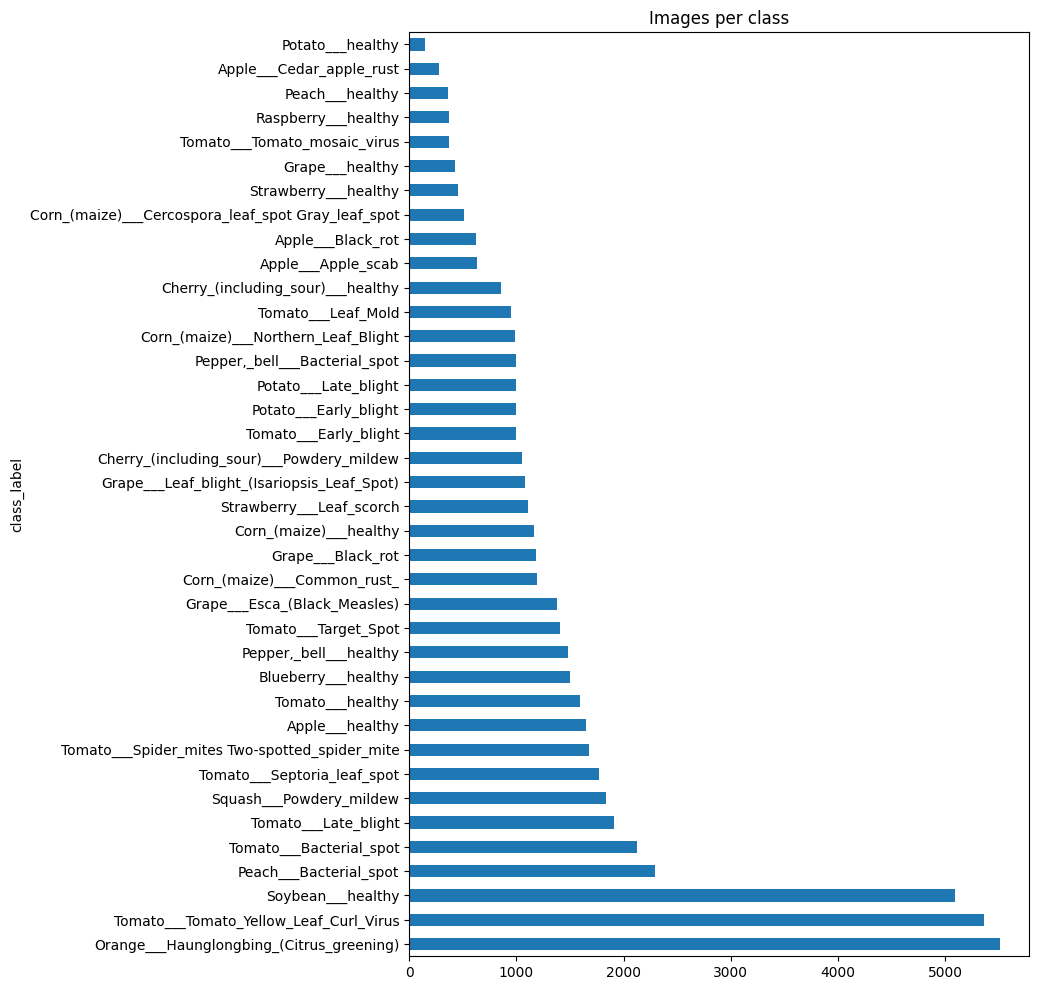

In [43]:
from matplotlib import pyplot as plt

class_counts = meta["class_label"].value_counts().sort_values()
ax = class_counts.plot(kind="barh", figsize=(10, 12))
ax.set_title("Images per disease class")
ax.set_xlabel("Number of images")
ax.set_ylabel("Disease class")
plt.tight_layout()
plt.show()


In [5]:
sel = meta[meta.host.str.contains("tomato|apple|corn", case=False)]
print(sel.groupby(["host", "class_label"]).size())
print(len(sel), "images,", sel.class_label.nunique(), "classes")

host          class_label                                       
Apple         Apple___Apple_scab                                     630
              Apple___Black_rot                                      621
              Apple___Cedar_apple_rust                               275
              Apple___healthy                                       1645
Corn (maize)  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     513
              Corn_(maize)___Common_rust_                           1192
              Corn_(maize)___Northern_Leaf_Blight                    985
              Corn_(maize)___healthy                                1162
Tomato        Tomato___Bacterial_spot                               2127
              Tomato___Early_blight                                 1000
              Tomato___Late_blight                                  1909
              Tomato___Leaf_Mold                                     952
              Tomato___Septoria_leaf_spot                  

## 8. Review sample images by class

Visual inspection can reveal label noise, confusing disease categories, background variation, and differences in lighting or image quality. The helper below displays a reproducible sample for each selected class.


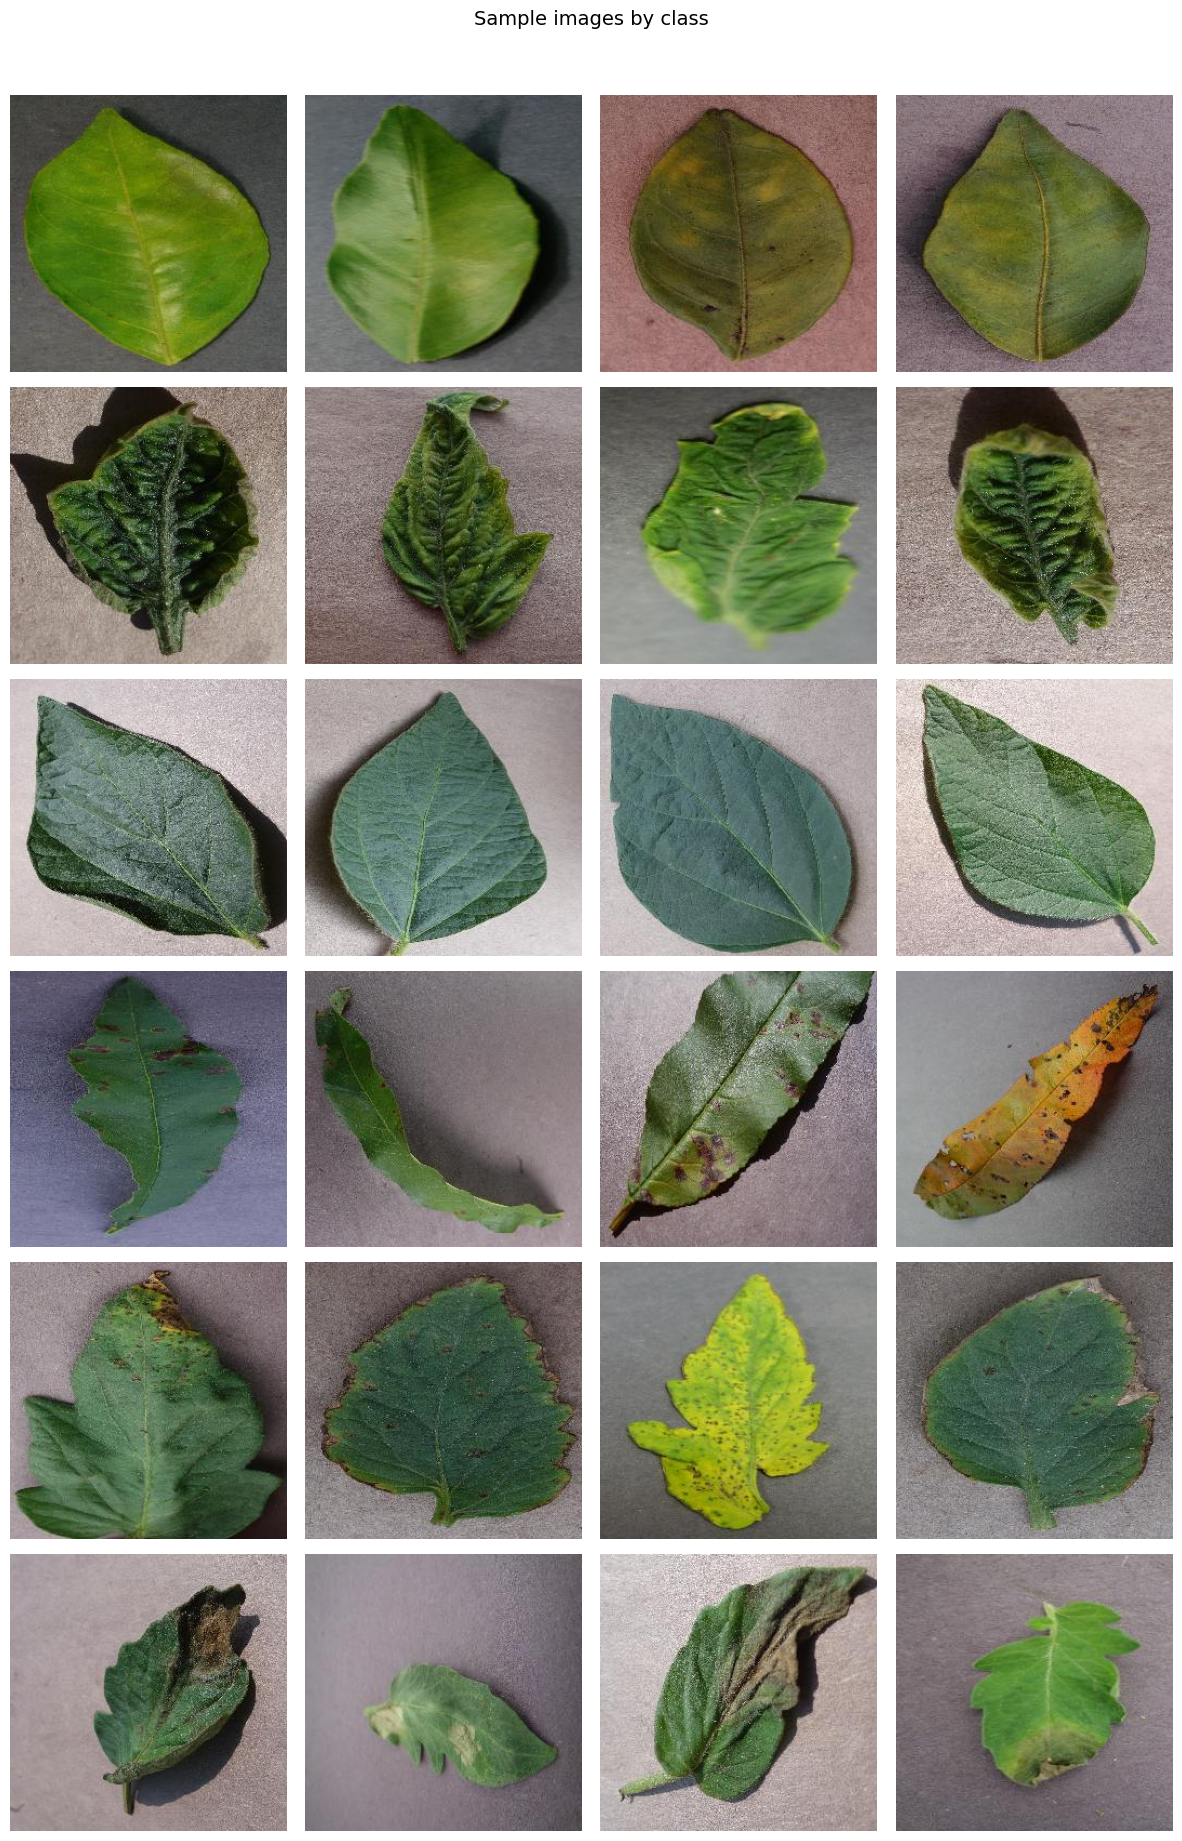

In [8]:
from io import BytesIO
from pathlib import Path
from PIL import Image


def load_image(image_record):
    if hasattr(image_record, "convert"):
        return image_record.convert("RGB")
    if image_record.get("bytes") is not None:
        return Image.open(BytesIO(image_record["bytes"])).convert("RGB")
    if image_record.get("path") is not None:
        return Image.open(Path(image_record["path"])).convert("RGB")
    raise ValueError("Image record contains neither bytes nor path")


def show_samples_by_class(labels=None, samples_per_class=4, seed=0):
    if labels is None:
        labels = meta["class_label"].value_counts().head(6).index.tolist()

    figure, axes = plt.subplots(
        len(labels), samples_per_class,
        figsize=(3 * samples_per_class, 3 * len(labels)),
        squeeze=False,
    )

    for row, label in enumerate(labels):
        class_rows = meta[meta["class_label"] == label]
        sample_rows = class_rows.sample(
            n=min(samples_per_class, len(class_rows)),
            random_state=seed,
        )
        sample_indices = sample_rows.index.tolist()

        for column in range(samples_per_class):
            axis = axes[row, column]
            axis.axis("off")
            if column < len(sample_indices):
                image = load_image(d[int(sample_indices[column])]["image"])
                axis.imshow(image)
            if column == 0:
                axis.set_ylabel(label, rotation=0, ha="right", va="center", labelpad=45)

    figure.suptitle("Sample images by class", y=1.02, fontsize=14)
    figure.tight_layout()
    plt.show()


show_samples_by_class()


## 9. Inspect image dimensions

Image dimensions can vary across datasets and affect preprocessing choices. Measuring the raw dimensions helps determine whether resizing or aspect-ratio handling needs special attention.


In [9]:
from collections import Counter

image_sizes = Counter(load_image(d[index]["image"]).size for index in range(len(d)))
size_summary = pd.DataFrame(
    [(width, height, count) for (width, height), count in image_sizes.items()],
    columns=["width", "height", "images"],
).sort_values("images", ascending=False)

display(size_summary.head(15))
print(f"Unique image sizes: {len(size_summary)}")


,width,height,images
0,256,256,54304


Unique image sizes: 1


## 10. EDA takeaways

### Dataset size and number of disease classes:
  - size : 54304
  - healthy plant images : x
  - number of disease classes : 26
### Dominant and rare classes:
 - Dominant : orange___haunglongbing, Tomato___tomato_yellow_leaf_curl_virus
 - Rare: potato___healthy, apple_cedar_apple_rust
### Missing or duplicated metadata:
 - Duplicate metadata: ??
### Image resizing and augmentation considerations: 
 - all images have one size 256 x 256.

These findings should be reviewed before building the training pipeline and selecting evaluation metrics.
